### Import libraries and load datasets :

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

os.makedirs("../visualizations", exist_ok=True)

df_user_engagement = pd.read_csv("../data/user_engagement.csv")
df_api_performance = pd.read_csv("../data/api_performance.csv")

print("User Engagement Shape:", df_user_engagement.shape)
print("API Performance Shape:", df_api_performance.shape)

display(df_user_engagement.head())
display(df_api_performance.head())

User Engagement Shape: (9999, 12)
API Performance Shape: (6, 13)


,user_id,active_days,total_events,total_sessions,total_api_requests,successful_api_requests,failed_api_requests,api_success_rate_percentage,first_activity_date,last_activity_date,activity_lifespan_days,engagement_segment
0,2993,1,1,1,0,0,0,NaN,2026-01-07,2026-01-07,0,Very Low Engagement
1,6905,1,1,1,0,0,0,NaN,2024-12-18,2024-12-18,0,Very Low Engagement
2,3503,1,1,1,0,0,0,NaN,2024-08-02,2024-08-02,0,Very Low Engagement
3,9846,1,1,1,0,0,0,NaN,2025-02-13,2025-02-13,0,Very Low Engagement
4,6294,1,1,1,283,266,17,93.99,2025-08-11,2025-08-11,0,Very Low Engagement


,endpoint,total_api_records,total_users,total_requests,successful_requests,failed_requests,error_rate_percentage,success_rate_percentage,average_response_time_ms,maximum_response_time_ms,error_rate_rank,response_time_rank,api_health_status
0,/api/v1/products,8353,5643,4161118,3952082,209036,5.02,94.98,506.25,999.61,1,6,Needs Improvement
1,/api/v1/webhooks,8222,5636,4129971,3923105,206866,5.01,94.99,510.68,999.96,2,3,Needs Improvement
2,/api/v1/auth,8315,5647,4231665,4019824,211841,5.01,94.99,508.95,999.76,2,5,Needs Improvement
3,/api/v1/orders,8383,5628,4249354,4037237,212117,4.99,95.01,510.58,999.94,3,4,Healthy
4,/api/v1/analytics,8298,5604,4211661,4001543,210118,4.99,95.01,513.88,999.97,3,1,Healthy


### Inspect numeric columns:

In [2]:
user_numeric = df_user_engagement.select_dtypes(include="number")
api_numeric = df_api_performance.select_dtypes(include="number")

print("User Numeric Columns:")
print(user_numeric.columns.tolist())

print("\nAPI Numeric Columns:")
print(api_numeric.columns.tolist())

User Numeric Columns:
['user_id', 'active_days', 'total_events', 'total_sessions', 'total_api_requests', 'successful_api_requests', 'failed_api_requests', 'api_success_rate_percentage', 'activity_lifespan_days']

API Numeric Columns:
['total_api_records', 'total_users', 'total_requests', 'successful_requests', 'failed_requests', 'error_rate_percentage', 'success_rate_percentage', 'average_response_time_ms', 'maximum_response_time_ms', 'error_rate_rank', 'response_time_rank']


### User engagement correlation matrix:

In [3]:
user_corr = user_numeric.corr(method="pearson")

display(user_corr.round(3))

user_corr.to_csv(
    "../data/user_engagement_correlation_matrix.csv"
)

,user_id,active_days,total_events,total_sessions,total_api_requests,successful_api_requests,failed_api_requests,api_success_rate_percentage,activity_lifespan_days
user_id,1.000,-0.005,-0.003,-0.003,-0.006,-0.006,-0.004,-0.014,-0.001
active_days,-0.005,1.000,0.948,0.948,0.801,0.801,0.790,-0.008,0.494
total_events,-0.003,0.948,1.000,1.000,0.687,0.687,0.678,-0.008,0.475
total_sessions,-0.003,0.948,1.000,1.000,0.687,0.687,0.678,-0.008,0.475
total_api_requests,-0.006,0.801,0.687,0.687,1.000,1.000,0.986,-0.010,0.389
successful_api_requests,-0.006,0.801,0.687,0.687,1.000,1.000,0.985,-0.003,0.389
failed_api_requests,-0.004,0.790,0.678,0.678,0.986,0.985,1.000,-0.142,0.385
api_success_rate_percentage,-0.014,-0.008,-0.008,-0.008,-0.010,-0.003,-0.142,1.000,-0.016
activity_lifespan_days,-0.001,0.494,0.475,0.475,0.389,0.389,0.385,-0.016,1.000


### User engagement correlation heatmap:

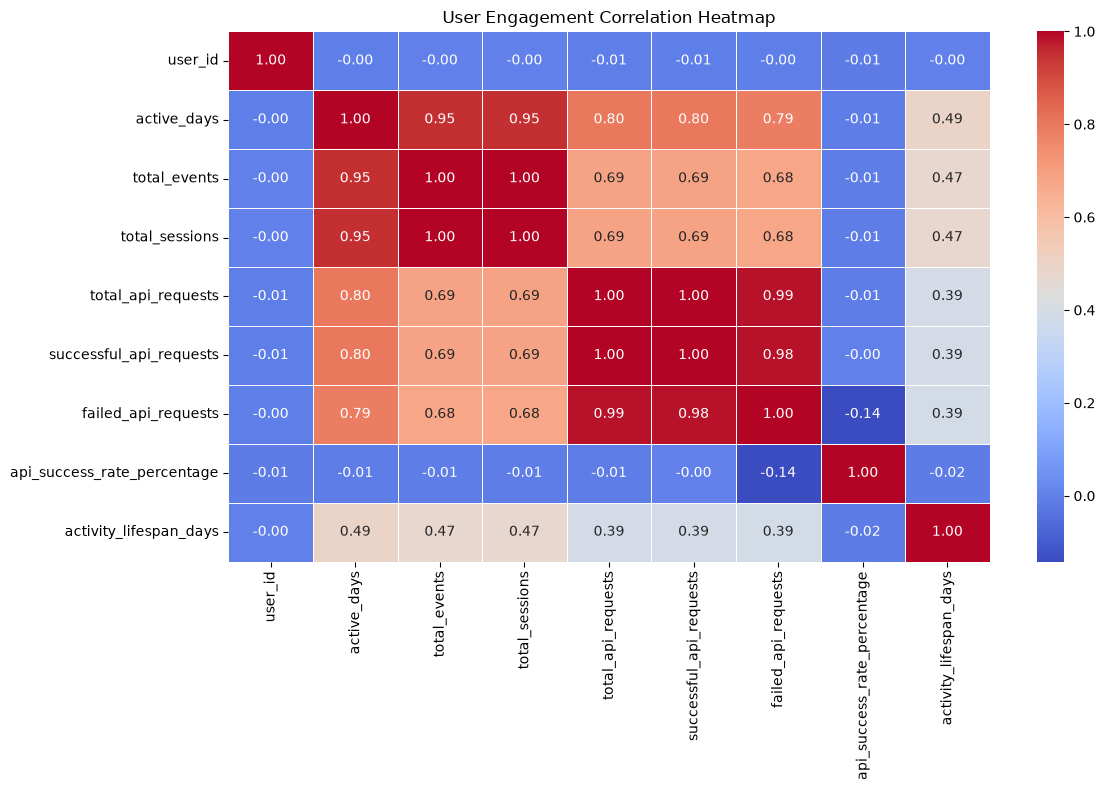

In [4]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    user_corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("User Engagement Correlation Heatmap")
plt.tight_layout()

plt.savefig(
    "../visualizations/user_engagement_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

### Active Days vs Total Events:

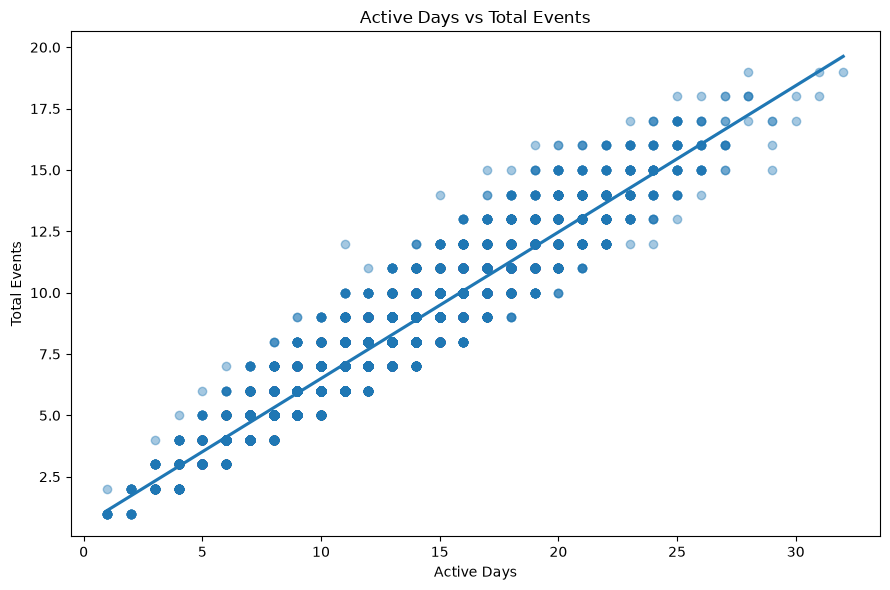

In [5]:
if {"active_days", "total_events"}.issubset(df_user_engagement.columns):

    plt.figure(figsize=(9, 6))

    sns.regplot(
        data=df_user_engagement,
        x="active_days",
        y="total_events",
        scatter_kws={"alpha": 0.4}
    )

    plt.title("Active Days vs Total Events")
    plt.xlabel("Active Days")
    plt.ylabel("Total Events")
    plt.tight_layout()

    plt.savefig(
        "../visualizations/active_days_vs_total_events.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

### Active Days vs Total API Requests:

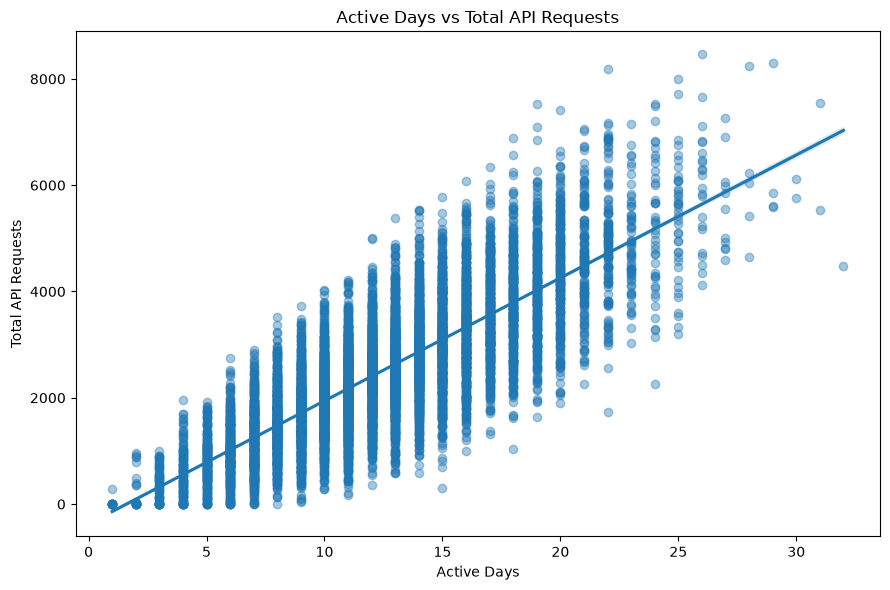

In [6]:
if {"active_days", "total_api_requests"}.issubset(df_user_engagement.columns):

    plt.figure(figsize=(9, 6))

    sns.regplot(
        data=df_user_engagement,
        x="active_days",
        y="total_api_requests",
        scatter_kws={"alpha": 0.4}
    )

    plt.title("Active Days vs Total API Requests")
    plt.xlabel("Active Days")
    plt.ylabel("Total API Requests")
    plt.tight_layout()

    plt.savefig(
        "../visualizations/active_days_vs_api_requests.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

### Total Sessions vs Total API Requests:

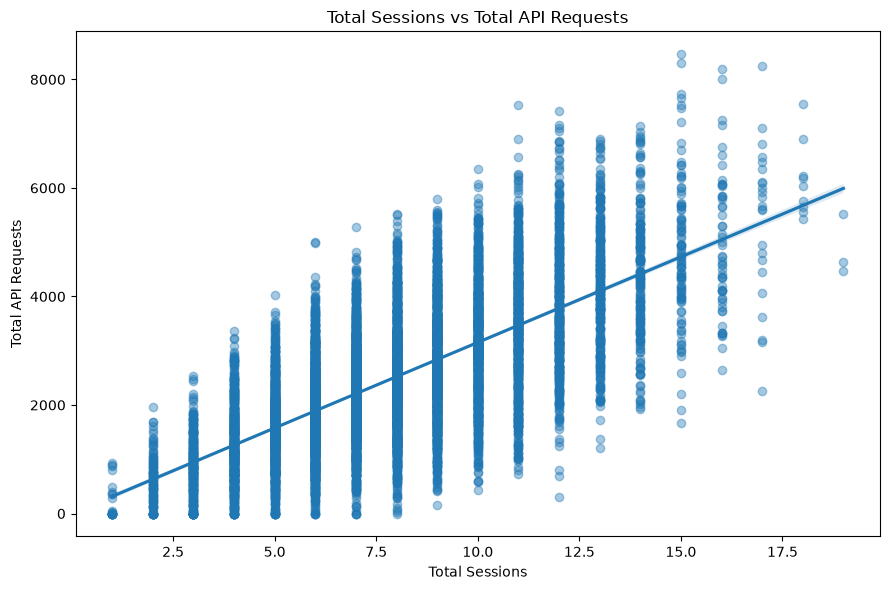

In [7]:
if {"total_sessions", "total_api_requests"}.issubset(df_user_engagement.columns):

    plt.figure(figsize=(9, 6))

    sns.regplot(
        data=df_user_engagement,
        x="total_sessions",
        y="total_api_requests",
        scatter_kws={"alpha": 0.4}
    )

    plt.title("Total Sessions vs Total API Requests")
    plt.xlabel("Total Sessions")
    plt.ylabel("Total API Requests")
    plt.tight_layout()

    plt.savefig(
        "../visualizations/sessions_vs_api_requests.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

### API performance correlation matrix:

In [8]:
api_corr = api_numeric.corr(method="pearson")

display(api_corr.round(3))

api_corr.to_csv(
    "../data/api_performance_correlation_matrix.csv"
)

,total_api_records,total_users,total_requests,successful_requests,failed_requests,error_rate_percentage,success_rate_percentage,average_response_time_ms,maximum_response_time_ms,error_rate_rank,response_time_rank
total_api_records,1.000,0.572,0.734,0.733,0.720,-0.592,0.592,-0.029,-0.238,0.492,0.070
total_users,0.572,1.000,0.242,0.243,0.194,-0.353,0.353,-0.164,-0.284,0.303,0.110
total_requests,0.734,0.242,1.000,1.000,0.967,-0.695,0.695,0.354,0.170,0.693,-0.195
successful_requests,0.733,0.243,1.000,1.000,0.964,-0.702,0.702,0.363,0.178,0.701,-0.205
failed_requests,0.720,0.194,0.967,0.964,1.000,-0.495,0.495,0.133,-0.028,0.489,0.041
error_rate_percentage,-0.592,-0.353,-0.695,-0.702,-0.495,1.000,-1.000,-0.765,-0.580,-0.987,0.728
success_rate_percentage,0.592,0.353,0.695,0.702,0.495,-1.000,1.000,0.765,0.580,0.987,-0.728
average_response_time_ms,-0.029,-0.164,0.354,0.363,0.133,-0.765,0.765,1.000,0.877,0.820,-0.973
maximum_response_time_ms,-0.238,-0.284,0.170,0.178,-0.028,-0.580,0.580,0.877,1.000,0.670,-0.819
error_rate_rank,0.492,0.303,0.693,0.701,0.489,-0.987,0.987,0.820,0.670,1.000,-0.764


### API performance correlation heatmap:

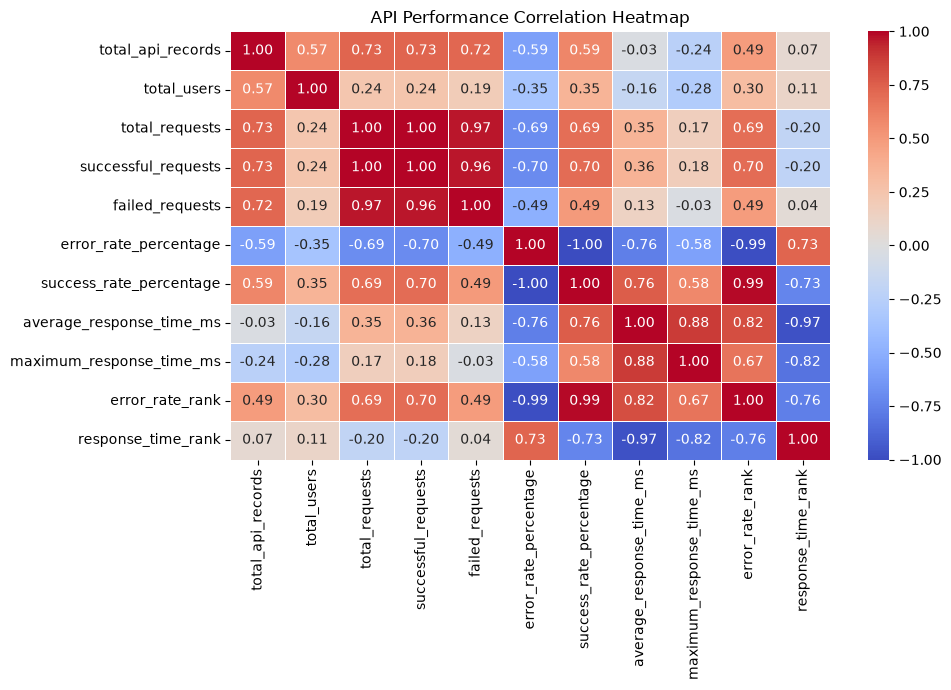

In [9]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    api_corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("API Performance Correlation Heatmap")
plt.tight_layout()

plt.savefig(
    "../visualizations/api_performance_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

### API Response Time vs Error Rate:

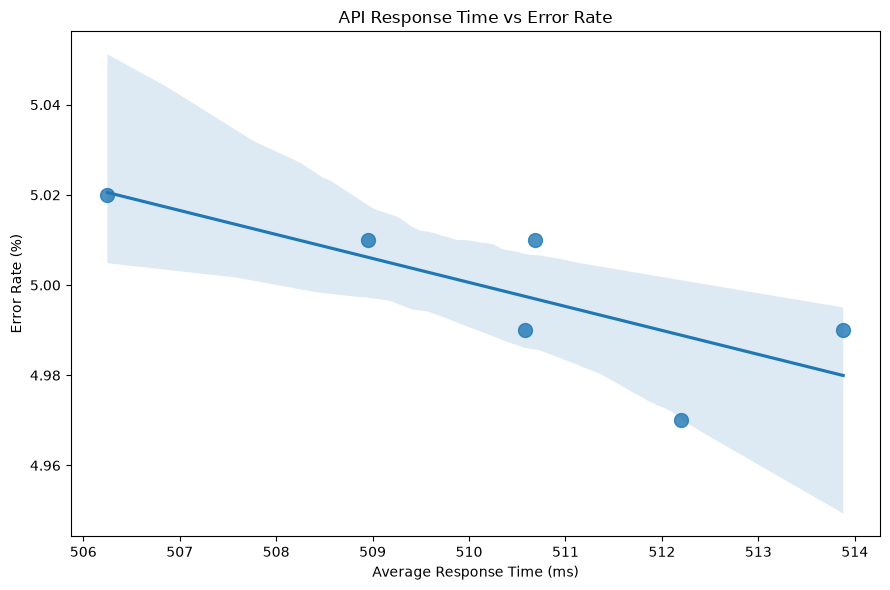

In [10]:
required_cols = [
    "average_response_time_ms",
    "error_rate_percentage"
]

if all(col in df_api_performance.columns for col in required_cols):

    plt.figure(figsize=(9, 6))

    sns.regplot(
        data=df_api_performance,
        x="average_response_time_ms",
        y="error_rate_percentage",
        scatter_kws={"s": 100}
    )

    plt.title("API Response Time vs Error Rate")
    plt.xlabel("Average Response Time (ms)")
    plt.ylabel("Error Rate (%)")
    plt.tight_layout()

    plt.savefig(
        "../visualizations/api_response_time_vs_error_rate_correlation.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

### Generate a correlation strength report :

In [11]:
correlation_report = (
    user_corr.where(
        np.triu(np.ones(user_corr.shape), k=1).astype(bool)
    )
    .stack()
    .reset_index()
)

correlation_report.columns = [
    "Metric_1",
    "Metric_2",
    "Correlation"
]

correlation_report["Absolute_Correlation"] = (
    correlation_report["Correlation"].abs()
)

correlation_report = correlation_report.sort_values(
    "Absolute_Correlation",
    ascending=False
)

display(correlation_report)

correlation_report.to_csv(
    "../data/user_engagement_correlation_report.csv",
    index=False
)

,Metric_1,Metric_2,Correlation,Absolute_Correlation
21,total_events,total_sessions,1.000000,1.000000
41,total_api_requests,successful_api_requests,0.999961,0.999961
42,total_api_requests,failed_api_requests,0.986141,0.986141
51,successful_api_requests,failed_api_requests,0.984635,0.984635
11,active_days,total_events,0.947973,0.947973
...,...,...,...,...
76,activity_lifespan_days,total_api_requests,NaN,NaN
77,activity_lifespan_days,successful_api_requests,NaN,NaN
78,activity_lifespan_days,failed_api_requests,NaN,NaN
79,activity_lifespan_days,api_success_rate_percentage,NaN,NaN


### Verify all saved files:

In [12]:
saved_files = [
    "user_engagement_correlation_heatmap.png",
    "active_days_vs_total_events.png",
    "active_days_vs_api_requests.png",
    "sessions_vs_api_requests.png",
    "api_performance_correlation_heatmap.png",
    "api_response_time_vs_error_rate_correlation.png"
]

for file in saved_files:
    path = os.path.join("../visualizations", file)

    print(
        "Saved:" if os.path.exists(path) else "Not found:",
        file
    )

Saved: user_engagement_correlation_heatmap.png
Saved: active_days_vs_total_events.png
Saved: active_days_vs_api_requests.png
Saved: sessions_vs_api_requests.png
Saved: api_performance_correlation_heatmap.png
Saved: api_response_time_vs_error_rate_correlation.png
